In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
import xgboost as xgb


df = pd.read_csv("wedding_budget_data.csv")

print(f"Dataset berhasil dibuat: {len(df)} baris, {len(df.columns)} kolom")
print(f"\nRentang total biaya: Rp{df['total_biaya'].min():,} - Rp{df['total_biaya'].max():,}")
print(f"Rata-rata total biaya: Rp{df['total_biaya'].mean():,.0f}")
print(f"\n=== 5 Baris Pertama Data ===")
print(df.head())

Dataset berhasil dibuat: 2000 baris, 6 kolom

Rentang total biaya: Rp37,028,563 - Rp380,255,467
Rata-rata total biaya: Rp142,012,541

=== 5 Baris Pertama Data ===
   jumlah_tamu      tipe_venue level_menu_catering jenis_dekorasi  \
0          152          Indoor            Ekonomis      Sederhana   
1          485  Indoor_Outdoor            Standard         Modern   
2          910          Indoor            Ekonomis      Sederhana   
3          320  Indoor_Outdoor            Standard      Sederhana   
4          156         Outdoor             Premium      Sederhana   

   bulan_pelaksanaan  total_biaya  
0                 11     38697393  
1                  6    146159162  
2                 10     94926347  
3                  9     84590627  
4                 11     71608894  


In [46]:
X = df.drop('total_biaya', axis=1)
y = df['total_biaya']

print("Fitur sebelum encoding:")
print(X.dtypes)
print(X.head())

X_encoded = pd.get_dummies(
    X,
    columns=['tipe_venue', 'level_menu_catering', 'jenis_dekorasi'],
    drop_first=True,
    dtype=int
)

print(f"\nFitur setelah encoding: {X_encoded.shape[1]} kolom")
print(X_encoded.head())

Fitur sebelum encoding:
jumlah_tamu            int64
tipe_venue               str
level_menu_catering      str
jenis_dekorasi           str
bulan_pelaksanaan      int64
dtype: object
   jumlah_tamu      tipe_venue level_menu_catering jenis_dekorasi  \
0          152          Indoor            Ekonomis      Sederhana   
1          485  Indoor_Outdoor            Standard         Modern   
2          910          Indoor            Ekonomis      Sederhana   
3          320  Indoor_Outdoor            Standard      Sederhana   
4          156         Outdoor             Premium      Sederhana   

   bulan_pelaksanaan  
0                 11  
1                  6  
2                 10  
3                  9  
4                 11  

Fitur setelah encoding: 9 kolom
   jumlah_tamu  bulan_pelaksanaan  tipe_venue_Indoor_Outdoor  \
0          152                 11                          0   
1          485                  6                          1   
2          910                 10      

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

print(f"Data latih: {X_train.shape}")
print(f"Data uji: {X_test.shape}")

scaler = StandardScaler()
kolom_numerik = ['jumlah_tamu', 'bulan_pelaksanaan']

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[kolom_numerik] = scaler.fit_transform(X_train_scaled[kolom_numerik])
X_test_scaled[kolom_numerik] = scaler.transform(X_test_scaled[kolom_numerik])

Data latih: (1600, 9)
Data uji: (400, 9)


In [48]:
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)

mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("\n=== Baseline Model: Linear Regression ===")
print(f"Mean Absolute Error (MAE) : Rp{mae_lr:,.0f}")
print(f"Root Mean Squared Error   : Rp{rmse_lr:,.0f}")
print(f"R-squared (R2)            : {r2_lr:.4f}")


=== Baseline Model: Linear Regression ===
Mean Absolute Error (MAE) : Rp19,628,272
Root Mean Squared Error   : Rp26,329,713
R-squared (R2)            : 0.8388


In [49]:
xgb_model = xgb.XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    subsample=1.0,
    random_state=42
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)

print("\n=== XGBoost (Default Parameter) ===")
print(f"n_estimators      : 100")
print(f"learning_rate     : 0.1")
print(f"max_depth         : 6")
print(f"subsample         : 1.0")
print(f"---")
print(f"Mean Absolute Error (MAE) : Rp{mae_xgb:,.0f}")
print(f"Root Mean Squared Error   : Rp{rmse_xgb:,.0f}")
print(f"R-squared (R2)            : {r2_xgb:.4f}")


=== XGBoost (Default Parameter) ===
n_estimators      : 100
learning_rate     : 0.1
max_depth         : 6
subsample         : 1.0
---
Mean Absolute Error (MAE) : Rp7,035,571
Root Mean Squared Error   : Rp9,495,734
R-squared (R2)            : 0.9790


In [50]:
xgb_base = xgb.XGBRegressor(random_state=42)

param_grid = {
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 5, 7, 10],
    'n_estimators': [100, 200, 300, 500],
    'subsample': [0.6, 0.8, 1.0]
}

grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)

print("Melakukan GridSearchCV...")
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)

mae_best = mean_absolute_error(y_test, y_pred_best)
rmse_best = np.sqrt(mean_squared_error(y_test, y_pred_best))
r2_best = r2_score(y_test, y_pred_best)

print("\n=== Hasil Hyperparameter Tuning ===")
print(f"Parameter Terbaik:")
print(f"  learning_rate : {grid_search.best_params_['learning_rate']}")
print(f"  max_depth     : {grid_search.best_params_['max_depth']}")
print(f"  n_estimators  : {grid_search.best_params_['n_estimators']}")
print(f"  subsample     : {grid_search.best_params_['subsample']}")
print(f"  Best CV Score (neg MAE) : {grid_search.best_score_:,.0f}")
print(f"\n=== Evaluasi Model Terbaik ===")
print(f"Mean Absolute Error (MAE) : Rp{mae_best:,.0f}")
print(f"Root Mean Squared Error   : Rp{rmse_best:,.0f}")
print(f"R-squared (R2)            : {r2_best:.4f}")

Melakukan GridSearchCV...
Fitting 5 folds for each of 192 candidates, totalling 960 fits

=== Hasil Hyperparameter Tuning ===
Parameter Terbaik:
  learning_rate : 0.05
  max_depth     : 3
  n_estimators  : 500
  subsample     : 0.6
  Best CV Score (neg MAE) : -6,316,348

=== Evaluasi Model Terbaik ===
Mean Absolute Error (MAE) : Rp6,351,530
Root Mean Squared Error   : Rp8,303,326
R-squared (R2)            : 0.9840


In [51]:
print("\n" + "="*70)
print("PERBANDINGAN KINERJA SELURUH MODEL")
print("="*70)
print(f"{'Model':<30} {'MAE (Rp)':<20} {'RMSE (Rp)':<20} {'R2':<10}")
print("-"*70)
print(f"{'Linear Regression':<30} Rp{mae_lr:<15,.0f} Rp{rmse_lr:<15,.0f} {r2_lr:<10.4f}")
print(f"{'XGBoost (Default)':<30} Rp{mae_xgb:<15,.0f} Rp{rmse_xgb:<15,.0f} {r2_xgb:<10.4f}")
print(f"{'XGBoost (Tuned)':<30} Rp{mae_best:<15,.0f} Rp{rmse_best:<15,.0f} {r2_best:<10.4f}")
print("="*70)
print(f"\nPeningkatan MAE dari Linear Regression ke XGBoost Tuned:")
print(f"  Rp{mae_lr - mae_best:,.0f} atau {((mae_lr - mae_best) / mae_lr) * 100:.1f}% lebih rendah")


PERBANDINGAN KINERJA SELURUH MODEL
Model                          MAE (Rp)             RMSE (Rp)            R2        
----------------------------------------------------------------------
Linear Regression              Rp19,628,272      Rp26,329,713      0.8388    
XGBoost (Default)              Rp7,035,571       Rp9,495,734       0.9790    
XGBoost (Tuned)                Rp6,351,530       Rp8,303,326       0.9840    

Peningkatan MAE dari Linear Regression ke XGBoost Tuned:
  Rp13,276,742 atau 67.6% lebih rendah



=== Feature Importance (Peringkat Fitur) ===
                       fitur  importance
 level_menu_catering_Premium    0.502813
                 jumlah_tamu    0.164860
level_menu_catering_Standard    0.135434
  jenis_dekorasi_Tradisional    0.043401
    jenis_dekorasi_Sederhana    0.041611
           bulan_pelaksanaan    0.039884
       jenis_dekorasi_Modern    0.037256
   tipe_venue_Indoor_Outdoor    0.028248
          tipe_venue_Outdoor    0.006492


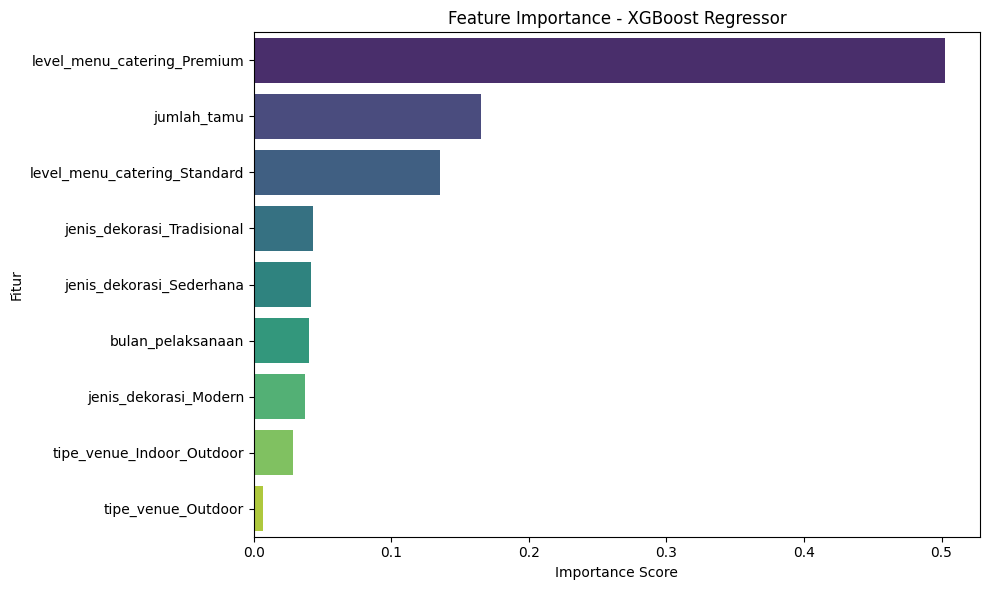

In [52]:
feature_importance = pd.DataFrame({
    'fitur': X_train.columns,
    'importance': best_model.feature_importances_
}).sort_values('importance', ascending=False)

print("\n=== Feature Importance (Peringkat Fitur) ===")
print(feature_importance.to_string(index=False))

# Visualisasi
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance,
    x='importance',
    y='fitur',
    palette='viridis'
)
plt.title('Feature Importance - XGBoost Regressor')
plt.xlabel('Importance Score')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

In [54]:
# Skenario 1: Pernikahan sederhana (100 tamu, Indoor, Ekonomis, Tradisional, Maret)
# Indoor = baseline (0,0), Ekonomis = baseline (0,0), Tradisional = 1, Sederhana = 0, Modern = 0
skenario1 = pd.DataFrame({
    'jumlah_tamu': [100],
    'bulan_pelaksanaan': [3],
    'tipe_venue_Indoor_Outdoor': [0],
    'tipe_venue_Outdoor': [0],
    'level_menu_catering_Premium': [0],
    'level_menu_catering_Standard': [0],
    'jenis_dekorasi_Modern': [0],
    'jenis_dekorasi_Sederhana': [0],
    'jenis_dekorasi_Tradisional': [1]
})

# Skenario 2: Pernikahan mewah (500 tamu, Kombinasi, Premium, Mewah, Desember)
# Mewah = baseline (0,0,0 karena di-drop)
skenario2 = pd.DataFrame({
    'jumlah_tamu': [500],
    'bulan_pelaksanaan': [12],
    'tipe_venue_Indoor_Outdoor': [1],
    'tipe_venue_Outdoor': [0],
    'level_menu_catering_Premium': [1],
    'level_menu_catering_Standard': [0],
    'jenis_dekorasi_Modern': [0],
    'jenis_dekorasi_Sederhana': [0],
    'jenis_dekorasi_Tradisional': [0]
})

# Skenario 3: Pernikahan menengah (250 tamu, Outdoor, Standard, Modern, Juni)
skenario3 = pd.DataFrame({
    'jumlah_tamu': [250],
    'bulan_pelaksanaan': [6],
    'tipe_venue_Indoor_Outdoor': [0],
    'tipe_venue_Outdoor': [1],
    'level_menu_catering_Premium': [0],
    'level_menu_catering_Standard': [1],
    'jenis_dekorasi_Modern': [1],
    'jenis_dekorasi_Sederhana': [0],
    'jenis_dekorasi_Tradisional': [0]
})

# Pastikan urutan kolom sama persis dengan X_train
skenario1 = skenario1[X_train.columns]
skenario2 = skenario2[X_train.columns]
skenario3 = skenario3[X_train.columns]

pred1 = best_model.predict(skenario1)[0]
pred2 = best_model.predict(skenario2)[0]
pred3 = best_model.predict(skenario3)[0]

print("\n=== SIMULASI ESTIMASI BIAYA PERNIKAHAN ===")
print("-"*70)
print(f"{'Skenario':<30} {'Estimasi Biaya':<20}")
print("-"*70)
print(f"{'Sederhana (100 tamu, Indoor, Ekonomis, Tradisional, Maret)':<30} Rp{pred1:<15,.0f}")
print(f"{'Mewah (500 tamu, Kombinasi, Premium, Mewah, Desember)':<30} Rp{pred2:<15,.0f}")
print(f"{'Menengah (250 tamu, Outdoor, Standard, Modern, Juni)':<30} Rp{pred3:<15,.0f}")
print("-"*70)


=== SIMULASI ESTIMASI BIAYA PERNIKAHAN ===
----------------------------------------------------------------------
Skenario                       Estimasi Biaya      
----------------------------------------------------------------------
Sederhana (100 tamu, Indoor, Ekonomis, Tradisional, Maret) Rp47,023,644     
Mewah (500 tamu, Kombinasi, Premium, Mewah, Desember) Rp243,074,864    
Menengah (250 tamu, Outdoor, Standard, Modern, Juni) Rp101,213,616    
----------------------------------------------------------------------
